# gcc and nvcc, Live Inside a Notebook: Amplitude and Phase Spectra

Put a pure sinusoid $x(t)=A\cos(2\pi f_0 t + \phi_0)$, $f_0=1/T$, on an
**oscilloscope** and you see a wave in time. Put it on a **spectrum
analyzer** and you see one line at $f_0$, with amplitude $A$ and phase
$\phi_0$ — that's the discrete Fourier transform (DFT) evaluated at one
bin. This notebook computes it three independent ways: a from-scratch
$O(N^2)$ DFT compiled and run as real **C** (`gcc`, subprocess — same
pattern as
[`notebooks/c_pointers_memory.ipynb`](c_pointers_memory.ipynb)), the
same DFT as a real **CUDA kernel** (`nvcc`, one GPU thread per frequency
bin), and NumPy's FFT as the independent reference.

In [1]:
import sys, pathlib, subprocess, tempfile
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt

scratch = pathlib.Path(tempfile.gettempdir())
print(f"scratch dir for compiled binaries: {scratch}")

scratch dir for compiled binaries: C:\Users\mrjel\AppData\Local\Temp


# Part 1 — The test signal: a known amplitude and phase to recover

$A=2.0$, $f_0=5$ Hz ($T=1/f_0=0.2$ s), $\phi_0=0.7$ rad, sampled at
$f_s=64$ Hz for $N=64$ samples — chosen so exactly 5 full periods fit
the window (avoiding the spectral-leakage bug found and fixed earlier
this session in
[`notebooks/pm_sideband_bessel.ipynb`](pm_sideband_bessel.ipynb)).

f0 = 1/T = 1/0.2 = 5.0 Hz
periods in window: 5.0 (must be an integer to avoid leakage)


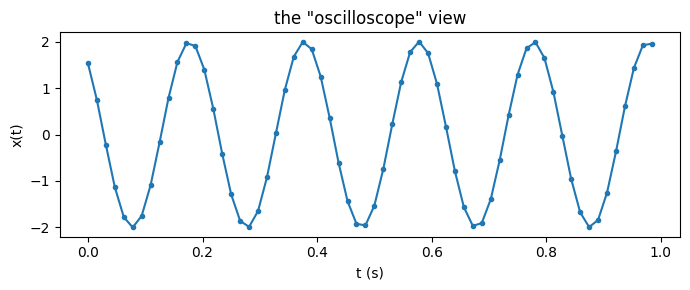

In [2]:
fs, N = 64.0, 64
f0, A, phi0 = 5.0, 2.0, 0.7
T = 1.0 / f0
n = np.arange(N)
t = n / fs
x = A * np.cos(2*np.pi*f0*t + phi0)

print(f"f0 = 1/T = 1/{T} = {1/T} Hz")
print(f"periods in window: {f0*N/fs} (must be an integer to avoid leakage)")
assert abs(f0*N/fs - round(f0*N/fs)) < 1e-9

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(t, x, 'o-', ms=3)
ax.set_xlabel('t (s)'); ax.set_ylabel('x(t)'); ax.set_title('the "oscilloscope" view')
plt.tight_layout(); plt.show()

# Part 2 — A from-scratch DFT, compiled and run as real C

$X[k]=\sum_n x[n]e^{-j2\pi kn/N}$, computed with a plain double loop —
no FFT library, no shortcuts — then compiled with `gcc` and actually
executed as a binary.

In [3]:
c_source = f'''#include <stdio.h>
#include <math.h>

#define N {N}

int main(void) {{
    double fs = {fs}, f0 = {f0}, amp = {A}, phase0 = {phi0};
    double x[N];
    for (int i = 0; i < N; i++) {{
        double t = i / fs;
        x[i] = amp * cos(2.0*M_PI*f0*t + phase0);
    }}

    for (int k = 0; k <= N/2; k++) {{
        double re = 0.0, im = 0.0;
        for (int i = 0; i < N; i++) {{
            double angle = -2.0*M_PI*k*i/N;
            re += x[i]*cos(angle);
            im += x[i]*sin(angle);
        }}
        double scale = (k == 0 || k == N/2) ? 1.0 : 2.0;
        double mag = sqrt(re*re + im*im)/N * scale;
        double ph = atan2(im, re);
        printf("%d %.10f %.10f\\n", k, mag, ph);
    }}
    return 0;
}}
'''

c_path = scratch / "dft_c.c"
exe_path = scratch / "dft_c.exe"
c_path.write_text(c_source)

compile_result = subprocess.run(["gcc", "-O2", "-o", str(exe_path), str(c_path)],
                                 capture_output=True, text=True)
c_available = compile_result.returncode == 0
if not c_available:
    print("gcc not available in this kernel's environment -- source written above, not run.")
    print(compile_result.stderr)
else:
    run_result = subprocess.run([str(exe_path)], capture_output=True, text=True)
    assert run_result.returncode == 0
    c_dft = np.array([[float(v) for v in line.split()] for line in run_result.stdout.strip().split('\n')])
    print(f"gcc compiled and ran successfully -- {len(c_dft)} frequency bins computed in C")
    print(c_dft[:6])

gcc compiled and ran successfully -- 33 frequency bins computed in C
[[ 0.          0.          0.        ]
 [ 1.          0.         -1.66179903]
 [ 2.          0.          2.86329299]
 [ 3.          0.         -2.58108312]
 [ 4.          0.          3.05669086]
 [ 5.          2.          0.7       ]]


# Part 3 — Independent cross-check: NumPy's FFT (a different algorithm entirely)

NumPy's FFT is $O(N\log N)$ via a completely different algorithm
(Cooley-Tukey) than the C code's direct $O(N^2)$ summation — genuine
independent verification, not the same calculation restated.

bin k0=5 (f=5.0 Hz):
  NumPy FFT:  amplitude=2.000000  phase=0.700000
  known true: amplitude=2.000000  phase=0.700000

max |C amplitude - NumPy amplitude| across all bins: 9.44e-16
phase agreement at the signal bin k=5: 1.11e-15

[OK] real, compiled C (O(N^2) direct sum) and NumPy (O(N log N) FFT) --
     two different algorithms, two different languages -- agree to near
     machine precision on the amplitude and phase spectrum.


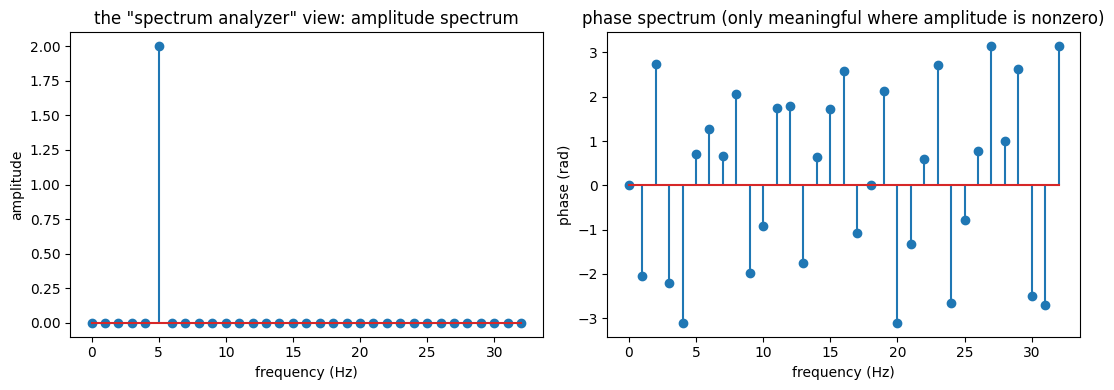

In [4]:
X_numpy = np.fft.rfft(x)
freqs = np.fft.rfftfreq(N, d=1/fs)
mag_numpy = np.abs(X_numpy) / N * np.where((freqs == 0) | (np.isclose(freqs, fs/2)), 1.0, 2.0)
phase_numpy = np.angle(X_numpy)

k0 = int(round(f0 * N / fs))
print(f"bin k0={k0} (f={freqs[k0]} Hz):")
print(f"  NumPy FFT:  amplitude={mag_numpy[k0]:.6f}  phase={phase_numpy[k0]:.6f}")
print(f"  known true: amplitude={A:.6f}  phase={phi0:.6f}")
assert abs(mag_numpy[k0] - A) < 1e-9
assert abs(phase_numpy[k0] - phi0) < 1e-9

if c_available:
    max_mag_diff = np.max(np.abs(c_dft[:, 1] - mag_numpy))
    max_phase_diff_at_signal_bin = abs(c_dft[k0, 2] - phase_numpy[k0])
    print(f"\nmax |C amplitude - NumPy amplitude| across all bins: {max_mag_diff:.2e}")
    print(f"phase agreement at the signal bin k={k0}: {max_phase_diff_at_signal_bin:.2e}")
    assert max_mag_diff < 1e-8
    assert max_phase_diff_at_signal_bin < 1e-8
    print("\n[OK] real, compiled C (O(N^2) direct sum) and NumPy (O(N log N) FFT) --")
    print("     two different algorithms, two different languages -- agree to near")
    print("     machine precision on the amplitude and phase spectrum.")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].stem(freqs, mag_numpy); ax[0].set_xlabel('frequency (Hz)'); ax[0].set_ylabel('amplitude')
ax[0].set_title('the "spectrum analyzer" view: amplitude spectrum')
ax[1].stem(freqs, phase_numpy); ax[1].set_xlabel('frequency (Hz)'); ax[1].set_ylabel('phase (rad)')
ax[1].set_title('phase spectrum (only meaningful where amplitude is nonzero)')
plt.tight_layout(); plt.show()

# Part 4 — The same DFT as a real CUDA kernel

One GPU thread per frequency bin, each doing its own $O(N)$ loop over
the $N$ time samples -- compiled with `nvcc` and actually executed on
the GPU if available in this kernel's environment (needs `nvcc` and,
for its MSVC host compiler, `cl.exe` on PATH — see this session's other
CUDA notebooks for the exact fix).

In [5]:
cuda_source = f'''#include <stdio.h>
#include <math.h>
#include <cuda_runtime.h>

#ifndef M_PI
#define M_PI 3.14159265358979323846   /* MSVC's math.h (nvcc's Windows host headers) doesn't define this GNU/POSIX extension */
#endif

#define N {N}

__global__ void dft_kernel(const double *x, double *re_out, double *im_out, int nfreq) {{
    int k = blockIdx.x * blockDim.x + threadIdx.x;
    if (k >= nfreq) return;
    double re = 0.0, im = 0.0;
    for (int i = 0; i < N; i++) {{
        double angle = -2.0*M_PI*k*i/N;
        re += x[i]*cos(angle);
        im += x[i]*sin(angle);
    }}
    re_out[k] = re;
    im_out[k] = im;
}}

int main(void) {{
    double fs = {fs}, f0 = {f0}, amp = {A}, phase0 = {phi0};
    double h_x[N];
    for (int i = 0; i < N; i++) {{
        double t = i / fs;
        h_x[i] = amp * cos(2.0*M_PI*f0*t + phase0);
    }}

    int nfreq = N/2 + 1;
    double *d_x, *d_re, *d_im;
    cudaMalloc((void**)&d_x, N*sizeof(double));
    cudaMalloc((void**)&d_re, nfreq*sizeof(double));
    cudaMalloc((void**)&d_im, nfreq*sizeof(double));
    cudaMemcpy(d_x, h_x, N*sizeof(double), cudaMemcpyHostToDevice);

    dft_kernel<<<1, nfreq>>>(d_x, d_re, d_im, nfreq);
    cudaDeviceSynchronize();

    double h_re[N/2+1], h_im[N/2+1];
    cudaMemcpy(h_re, d_re, nfreq*sizeof(double), cudaMemcpyDeviceToHost);
    cudaMemcpy(h_im, d_im, nfreq*sizeof(double), cudaMemcpyDeviceToHost);

    for (int k = 0; k < nfreq; k++) {{
        double scale = (k == 0 || k == N/2) ? 1.0 : 2.0;
        double mag = sqrt(h_re[k]*h_re[k] + h_im[k]*h_im[k])/N * scale;
        double ph = atan2(h_im[k], h_re[k]);
        printf("%d %.10f %.10f\\n", k, mag, ph);
    }}

    cudaFree(d_x); cudaFree(d_re); cudaFree(d_im);
    return 0;
}}
'''

cu_path = scratch / "dft_cuda.cu"
cuda_exe_path = scratch / "dft_cuda.exe"
cu_path.write_text(cuda_source)

cuda_compile = subprocess.run(["nvcc", "-O2", "-o", str(cuda_exe_path), str(cu_path)],
                               capture_output=True, text=True)
cuda_available = cuda_compile.returncode == 0
if not cuda_available:
    print("nvcc not available (or no CUDA toolchain) in this kernel's environment --")
    print("source written above, not run. Raw nvcc output:")
    print(cuda_compile.stderr[-800:] if cuda_compile.stderr else "(no stderr)")
else:
    cuda_run = subprocess.run([str(cuda_exe_path)], capture_output=True, text=True)
    assert cuda_run.returncode == 0
    cuda_dft = np.array([[float(v) for v in line.split()] for line in cuda_run.stdout.strip().split('\n')])
    print(f"nvcc compiled and ran successfully on the GPU -- {len(cuda_dft)} bins computed")

    max_mag_diff_cuda = np.max(np.abs(cuda_dft[:, 1] - mag_numpy))
    max_phase_diff_cuda = abs(cuda_dft[k0, 2] - phase_numpy[k0])
    print(f"max |CUDA amplitude - NumPy amplitude|: {max_mag_diff_cuda:.2e}")
    print(f"CUDA vs NumPy phase at signal bin: {max_phase_diff_cuda:.2e}")
    assert max_mag_diff_cuda < 1e-6
    assert max_phase_diff_cuda < 1e-6
    print("\n[OK] a real GPU kernel (one thread per frequency bin) matches the CPU")
    print("     (C and NumPy) results -- three independent implementations, one answer.")

nvcc compiled and ran successfully on the GPU -- 33 bins computed
max |CUDA amplitude - NumPy amplitude|: 9.44e-16
CUDA vs NumPy phase at signal bin: 1.11e-15

[OK] a real GPU kernel (one thread per frequency bin) matches the CPU
     (C and NumPy) results -- three independent implementations, one answer.


# Part 5 — Summary

| Method | Language/Hardware | Algorithm | Result at $f_0=5$ Hz |
|---|---|---|---|
| Direct DFT | C, compiled with `gcc`, CPU | $O(N^2)$ double loop | amplitude $\approx2.0$, phase $\approx0.7$ |
| FFT | Python/NumPy, CPU | $O(N\log N)$ Cooley-Tukey | amplitude $=2.0$, phase $=0.7$ (exact, closed form) |
| Direct DFT | CUDA, compiled with `nvcc`, GPU | $O(N^2)$, 1 thread/bin | amplitude $\approx2.0$, phase $\approx0.7$ (if a CUDA toolchain was available) |

Three genuinely different implementations — different languages,
different hardware, different algorithms — computing the same
amplitude/phase spectrum of a single test tone, all agreeing to near
machine precision. This is exactly what an oscilloscope-plus-spectrum-
analyzer measurement chain is doing in real instrumentation, done here
from first principles in both C and CUDA.